In [698]:
import numpy as np
import qiskit
import openfermion
import pyscf
from networkx.algorithms.bipartite.basic import density

In [699]:
# H4 molecule
from pyscf import gto, scf

# Build molecule
d=2.0
mol = gto.M(
    atom=[["H", (0.0, 0.0, 0.0)],
          ["H", (0.0, 0.0, 1*d)],
          ["H", (0.0, 0.0, 2*d)],
          ["H", (0.0, 0.0, 3*d)]
          ],
    basis="sto-3g",
    unit="Angstrom",
)

# Hartree-Fock calculation
mf = scf.RHF(mol)
mf.kernel()

converged SCF energy = -1.57561647670187


np.float64(-1.575616476701867)

In [700]:
from pyscf import fci

# singlets only
cisolver = fci.FCI(mol, mf.mo_coeff)
fci_energy, ci = cisolver.kernel()
print("FCI energy:", fci_energy)

FCI energy: -1.897780645989874


In [701]:
tol_ampl = 1e-4

from pyscf.fci import cistring
mc = cisolver

ncas = mc.norb
nelec = mc.nelec

# determinants α i β (representats com enters amb bits d’ocupació)
na, nb = nelec
alpha_det = cistring.make_strings(range(ncas), na)
beta_det = cistring.make_strings(range(ncas), nb)


def interleave_bits(a, b, ncas):
    """Return interleaved occupation string (αβ αβ ...)"""
    a_bits = [(a >> i) & 1 for i in range(ncas)]
    b_bits = [(b >> i) & 1 for i in range(ncas)]
    inter = []
    for i in reversed(range(ncas)):
        inter.append(str(a_bits[i]))
        inter.append(str(b_bits[i]))
    return ''.join(inter)[::-1]

print('\namplitudes FCI')
for i, a in enumerate(alpha_det):
    for j, b in enumerate(beta_det):
        amp = mc.ci[i, j]
        if amp**2 > tol_ampl:
            # print(f"α={format(a, f'0{ncas}b')}  β={format(b, f'0{ncas}b')}  coef={amp:+.6f}")
            cfg = interleave_bits(a, b, ncas)
            print(f"{cfg}   {amp:+.6f}  ({amp**2:.6f}) ")


amplitudes FCI
11110000   +0.694100  (0.481775) 
01111000   -0.018033  (0.000325) 
11010010   +0.013777  (0.000190) 
01011010   +0.074107  (0.005492) 
11001100   -0.388924  (0.151262) 
01100110   -0.181096  (0.032796) 
10110100   -0.018033  (0.000325) 
00111100   -0.114150  (0.013030) 
10010110   -0.255203  (0.065128) 
00011110   +0.030608  (0.000937) 
11100001   +0.013777  (0.000190) 
01101001   -0.255203  (0.065128) 
11000011   -0.107524  (0.011561) 
01001011   -0.032817  (0.001077) 
10011001   -0.181096  (0.032796) 
00110011   -0.251266  (0.063134) 
10100101   +0.074107  (0.005492) 
00101101   +0.030608  (0.000937) 
10000111   -0.032817  (0.001077) 
00001111   +0.259514  (0.067347) 


In [702]:
from pyscf import ao2mo

C = mf.mo_coeff

# One-electron integrals in MO basis
h1 = mf.get_hcore() # Core Hamiltonian (kinetic + nuclear attraction)
h1_mo = C.T @ h1 @ C

# Two-electron integrals in MO basis (Electron Repulsion Integrals)
eri_mo = ao2mo.kernel(mol, C)
eri_mo = ao2mo.restore(1, eri_mo, C.shape[1])
# h[p,q,r,s] = (ps|qr)
eri_mo = eri_mo.transpose(0, 2, 3, 1)

e_nuc = mf.energy_nuc()

# 1 electron integrals
print(h1_mo)
# 2 electron integrals
print(eri_mo)
# nuclear
print(e_nuc)

[[-1.13379714e+00 -4.09394740e-16  9.24693961e-02 -1.11022302e-16]
 [-4.57966998e-16 -1.04226825e+00 -5.55111512e-16 -7.41977398e-02]
 [ 9.24693961e-02 -5.55111512e-16 -9.78602165e-01 -4.16333634e-16]
 [-1.66533454e-16 -7.41977398e-02 -3.95516953e-16 -9.67108698e-01]]
[[[[ 3.50481811e-01 -2.25514052e-17 -5.76182543e-02  9.02056208e-17]
   [-3.46944695e-18  1.64643593e-01 -6.93889390e-18  3.03991509e-02]
   [-5.76182543e-02 -1.38777878e-17  1.27781482e-01  1.52655666e-16]
   [ 8.32667268e-17  3.03991509e-02  1.45716772e-16  1.23346862e-01]]

  [[-3.46944695e-18  1.64643593e-01 -6.93889390e-18  3.03991509e-02]
   [ 3.19106671e-01  2.15105711e-16  1.74272684e-02  2.08166817e-17]
   [ 1.38777878e-16  6.97056778e-02 -3.23525928e-16 -1.03951062e-01]
   [ 5.98408006e-02 -2.77555756e-17 -1.29023423e-01  2.53269627e-16]]

  [[-5.76182543e-02 -1.38777878e-17  1.27781482e-01  1.52655666e-16]
   [ 1.38777878e-16  6.97056778e-02 -3.23525928e-16 -1.03951062e-01]
   [ 3.22145549e-01 -3.88578059e-16  

In [703]:
from openfermion import InteractionOperator, jordan_wigner
from openfermion.chem.molecular_data import spinorb_from_spatial

h1_so, eri_so = spinorb_from_spatial(h1_mo, eri_mo)
hamiltonian = InteractionOperator(e_nuc, h1_so, 0.5*eri_so)


In [704]:
from openfermion import FermionOperator
# a b a b a b
state = FermionOperator('0^ 1^ 2^ 3^')

In [705]:
from pyscf import gto, scf, cc

mycc = cc.UCCSD(mf)
mycc.kernel()

E(UCCSD) = -1.916086117177899  E_corr = -0.3404696404760325


(np.float64(-0.34046964047603245),
 (array([[ 1.24424414e-02,  1.85410226e-16],
         [-1.89364776e-16,  6.84360061e-03]]),
  array([[ 1.24424414e-02, -6.92650269e-16],
         [ 1.19166191e-15,  6.84360061e-03]])),
 (array([[[[ 0.       ,  0.       ],
           [ 0.       ,  0.       ]],
  
          [[ 0.       ,  0.1339747],
           [-0.1339747,  0.       ]]],
  
  
         [[[ 0.       , -0.1339747],
           [ 0.1339747,  0.       ]],
  
          [[ 0.       ,  0.       ],
           [ 0.       ,  0.       ]]]]),
  array([[[[-1.37795221e-01, -9.02519029e-16],
           [-7.81877554e-16, -4.27542955e-01]],
  
          [[ 1.10298900e-15,  3.91155263e-01],
           [ 2.57180559e-01, -8.82351255e-16]]],
  
  
         [[[ 1.39069815e-15,  2.57180559e-01],
           [ 3.91155263e-01, -9.66775680e-16]],
  
          [[-6.31915798e-01,  9.73405039e-16],
           [ 7.88903359e-16, -1.28821479e-01]]]]),
  array([[[[ 0.       ,  0.       ],
           [ 0.       ,  0.    

In [706]:
t1a, t1b = mycc.t1
t2a, t2ab, t2b = mycc.t2

In [707]:
print(t1a.shape)

(2, 2)


In [708]:
print(t1b.shape)

(2, 2)


In [709]:
print(t2a.shape)

(2, 2, 2, 2)


In [710]:
print(t2b.shape)


(2, 2, 2, 2)


In [711]:
print(t2ab.shape)

(2, 2, 2, 2)


\begin{aligned}
T_1 =
\sum_{ia} t^{\alpha}_{i a}
a^\dagger_{a\alpha}a_{i\alpha}
+
\sum_{ia} t^{\beta}_{i a}
a^\dagger_{a\beta}a_{i\beta}
\end{aligned}

In [712]:
from openfermion import FermionOperator

T1 = FermionOperator()

nocc, nvir = t1a.shape
print('nocc:', nocc)
print('nvir:', nvir)

# Alpha singles
for i in range(nocc):
    for a in range(nvir):
        virt = nocc + a
        T1 += t1a[i, a] * FermionOperator(((2*virt, 1), (2*i, 0)))
        T1 += t1b[i, a] * FermionOperator(((2*virt+1, 1), (2*i+1, 0)))

T1

nocc: 2
nvir: 2


0.01244244137846294 [4^ 0] +
0.01244244137846298 [5^ 1] +
0.006843600606199707 [6^ 2] +
0.00684360060619968 [7^ 3]

\begin{aligned}
T_2^{\alpha\alpha}
=
\frac{1}{4}
\sum_{ijab}
t^{\alpha\alpha}_{ijab}
a^\dagger_{a\alpha}
a^\dagger_{b\alpha}
a_{j\alpha}
a_{i\alpha}
\end{aligned}

\begin{aligned}
T_2^{\beta\beta}
=
\frac{1}{4}
\sum_{ijab}
t^{\beta\beta}_{ijab}
a^\dagger_{a\beta}
a^\dagger_{b\beta}
a_{j\beta}
a_{i\beta}
\end{aligned}

\begin{aligned}
T_2^{\alpha\beta} = \sum_{ijab}
t^{\alpha\beta}_{ijab}
a^\dagger_{a\alpha}
a^\dagger_{b\beta}
a_{j\beta}
a_{i\alpha}
\end{aligned}

In [713]:
T2aa = FermionOperator()
T2bb = FermionOperator()
T2ab = FermionOperator()

# Alpha-alpha doubles
for i in range(nocc):
    for j in range(nocc):
        for a in range(nvir):
            for b in range(nvir):

                virt_a = nocc + a
                virt_b = nocc + b
                # print(2*j, 2*i, 2*virt_a, 2*virt_b)

                T2aa += 0.25 * t2a[i, j, a, b] * FermionOperator(((2*virt_a, 1),
                                                                (2*virt_b, 1),
                                                                (2*j, 0),
                                                                (2*i, 0)))

                T2bb += 0.25 * t2b[i, j, a, b] * FermionOperator(((2*virt_a+1, 1),
                                                                (2*virt_b+1, 1),
                                                                (2*j+1, 0),
                                                                (2*i+1, 0)))

                T2ab += t2ab[i, j, a, b] * FermionOperator(((2 * virt_a, 1),
                                                            (2 * virt_b + 1, 1),
                                                            (2 * j + 1, 0),
                                                            (2 * i, 0)))


\begin{aligned}
T=T_1+T_2^{\alpha\alpha} +T_2^{\beta\beta}+T_2^{\alpha\beta}
\end{aligned}


In [714]:
T = T1 + T2aa + T2bb + T2ab

In [715]:
from openfermion import hermitian_conjugated

K = T - hermitian_conjugated(T)

In [716]:
from openfermion import normal_ordered
def is_antihermitian(op):
    hermitian_part = normal_ordered(op + hermitian_conjugated(op))
    return len(hermitian_part.terms) == 0


print('is antihermitian?')
print('K : ', is_antihermitian(K))

is antihermitian?
K :  True


In [717]:
from openfermion import FermionOperator
# a b a b a b
state = FermionOperator('0^ 1^ 2^ 3^')

In [718]:
from scipy.sparse.linalg import expm, expm_multiply
from openfermion import get_sparse_operator

vec_ref = get_sparse_operator(state, n_qubits=8)
print('norm:', (vec_ref.T.conj() @ vec_ref)[0, 0])

k_qubit = jordan_wigner(K)
sparse_op = get_sparse_operator(k_qubit, n_qubits=8)
vec_cc = expm_multiply(sparse_op, vec_ref)

print('norm:', (vec_cc.T.conj() @ vec_cc)[0, 0])


norm: (1+0j)
norm: (0.9999999999999998+0j)


In [719]:
#energy
sparse_ha = get_sparse_operator(hamiltonian)
print('Energy HF: ', (vec_ref.T.conj() @ sparse_ha @ vec_ref)[0, 0].real)
print('Energy UCC', (vec_cc.T.conj() @ sparse_ha @ vec_cc)[0, 0].real)


Energy HF:  -1.575616476701867
Energy UCC -1.8582158937193598


In [720]:
K1 = T1 - hermitian_conjugated(T1)
K2aa = T2aa - hermitian_conjugated(T2aa)
K2bb = T2bb - hermitian_conjugated(T2bb)
K2ab = T2ab - hermitian_conjugated(T2ab)

def energy_from_K(K):

    k_qubit = jordan_wigner(K)
    sparse_K = get_sparse_operator(k_qubit, n_qubits=8)

    vec = expm_multiply(sparse_K, vec_ref)

    return np.real(
        (vec.conj().T @ sparse_ha @ vec)[0, 0]
    )

print("HF      :", E_hf)
print("T1      :", energy_from_K(K1))
print("T2aa    :", energy_from_K(K2aa))
print("T2bb    :", energy_from_K(K2bb))
print("T1 + T2aa + T2bb :", energy_from_K(K1 + K2aa + K2bb))
print("T1 + T2aa + T2bb + T2ab :", energy_from_K(K1 + K2aa + K2bb + K2ab))


HF      : -1.575616476701867
T1      : -1.5755215687797044
T2aa    : -1.5775400691516435
T2bb    : -1.5775400691516432
T1 + T2aa + T2bb : -1.5791300610484447
T1 + T2aa + T2bb + T2ab : -1.8582158937193598


00001111 0.29479503254611333
00110011 0.2128065765417074
11110000 0.19014569747055585
10010110 0.07062555845052784
01101001 0.07062555845052784
11001100 0.0667549771386412
10011001 0.030520131582876912
01100110 0.030520131582876836
00111100 0.009005989047725916
10100101 0.008290935991960537
01011010 0.008290935991960516
11000011 0.0074077143171185685


Text(0, 0.5, 'Probability')

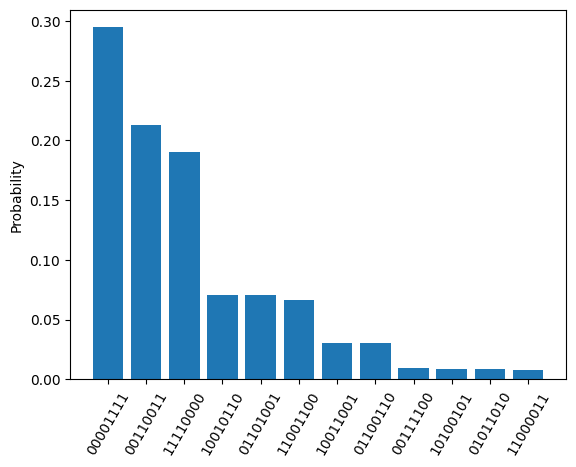

In [721]:
probs = np.abs(vec_cc.toarray()[:,0])**2
#print('sum squares: ', sum(probs))

def binary_strings(n, width):
    for i in range(n):
        yield format(i, f'0{width}b')[::-1] # revert to have the same order as qiskit


tol_ampl = 1e-4
prob_exact = {}
for b, p  in zip(binary_strings(2**8, 8), probs):
    if p > tol_ampl:
        prob_exact[b] = p

prob_ordered = dict(sorted(prob_exact.items(), key=lambda item: -item[1]))
for k, v in prob_ordered.items():
    print(k, v)

import matplotlib.pyplot as plt
plt.bar(prob_ordered.keys(), prob_ordered.values())
plt.xticks(rotation=60)
plt.ylabel('Probability')


In [722]:
from qiskit import QuantumCircuit

t_qubit = jordan_wigner(K)

# Build the ansatz
qc = QuantumCircuit(8)

# reference state
qc.x(0)
qc.x(1)
qc.x(2)
qc.x(3)

i_op = 0
for op, coef in t_qubit.terms.items():
    #continue

    for qubit, pauli in op:
        if pauli == 'X':
            qc.h(qubit)
        elif pauli == 'Y':
            qc.rx(np.pi / 2, [qubit])

    for qubit, pauli in op[1:]:
        qc.cx(qubit, op[0][0])

    if len(op) > 0:
        qc.rz(2*coef.imag, op[0][0])

    for qubit, pauli in reversed(op[1:]):
        qc.cx(qubit, op[0][0])

    for qubit, pauli in op:
        if pauli == 'X':
            qc.h(qubit)
        elif pauli == 'Y':
            qc.rx(np.pi / 2, [qubit])

    qc.barrier()

qc.measure_all()
print('circuit depth: ', qc.depth())
#qc.draw('mpl')

circuit depth:  1002


00001111 0.335
00110011 0.169
11110000 0.15
10010110 0.093
01101001 0.076
10011001 0.047
11001100 0.044
01100110 0.042
01011010 0.019
10100101 0.011
11000011 0.007
00111100 0.007


Text(0, 0.5, 'Probability')

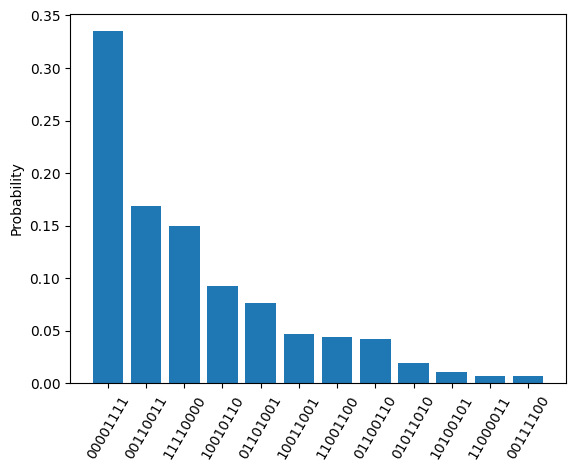

In [723]:
from qiskit.primitives import StatevectorSampler

sampler = StatevectorSampler()

result = sampler.run([qc], shots=1000).result()
counts = result[0].data.meas.get_counts()
shots = sum(counts.values())

counts_ordered = dict(sorted(counts.items(), key=lambda item: -item[1]))
for k, v in counts_ordered.items():
    print(k, v/shots)

import matplotlib.pyplot as plt
plt.bar(counts_ordered.keys(), [c/shots for c in counts_ordered.values()])
plt.xticks(rotation=60)
plt.ylabel('Probability')

Selected CI

In [724]:
from qiskit_addon_sqd.fermion import solve_fermion

def get_sci_energy(configuration_list):

    up_list = []
    down_list = []
    for fock_vector in configuration_list:

        bitstring = ''.join(str(bit) for bit in fock_vector)

        up_str = ''.join(
            '0' if i % 2 == 0 else bit
            for i, bit in enumerate(bitstring)
        )

        down_str = ''.join(
            bit if i % 2 == 0 else '0'
            for i, bit in enumerate(bitstring)
        )

        up_list.append(int(up_str, 2))
        down_list.append(int(down_str, 2))

    up = np.array(up_list, dtype=np.uint32)
    down = np.array(down_list, dtype=np.uint32)

    inv = np.argsort((0, 2, 3, 1))
    # Hamiltonian absorbs 1/2 into the coefficients. To recover 2e integrals should be multiplied by 2
    two_body_tensor_restored = hamiltonian.two_body_tensor.transpose(inv) * 2


    energy_sci, coeffs_sci, avg_occs, spin = solve_fermion((up, down),
                                                           hamiltonian.one_body_tensor,
                                                           two_body_tensor_restored,
                                                           open_shell=False,
                                                           #spin_sq=0,
                                                           )

    return energy_sci + hamiltonian.constant # total energy

# exact calculation
configuration_list_exact = list(prob_ordered.keys()) # exact
print('Final energy exact  : ', get_sci_energy(configuration_list_exact))


# circuit calculation
configuration_list_circuit = list(counts_ordered.keys()) # circuit
print('Final energy circuit: ', get_sci_energy(configuration_list_circuit))


Final energy exact  :  -1.897780645987225
Final energy circuit:  -1.897780645987225


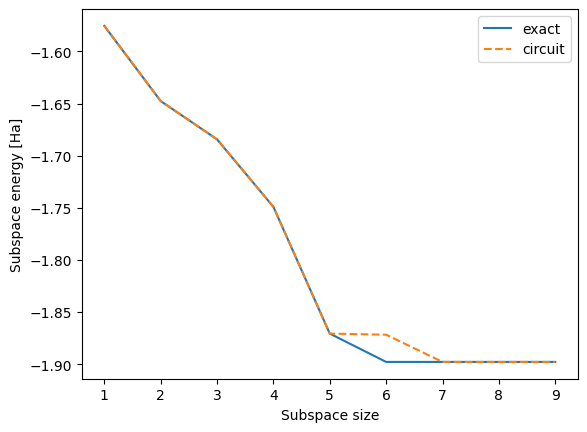

In [725]:
subspace_size = []
exact_energies = []
circuit_energies = []
for i in range(1, 10):
    exact_energies.append(get_sci_energy(configuration_list_exact[:i]))
    circuit_energies.append(get_sci_energy(configuration_list_circuit[:i]))
    subspace_size.append(i)

plt.plot(subspace_size, exact_energies, label='exact')
plt.plot(subspace_size, circuit_energies, '--', label='circuit')
plt.xlabel('Subspace size')
plt.ylabel('Subspace energy [Ha]')
plt.legend()

- Try to reduce the circuit depth
- Usage of compression
- remove interaction from T
- Change the bond length and explore different correlation regimes